# Statistical Analysis

Pairwise comparisons between the 3 ad platforms (Google Ads, Meta Ads, TikTok Ads), plus multiple comparisons correction.

Input: `data/marketing_data.csv` from `data_exploration.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control

daily = pd.read_csv('data/marketing_data.csv')
daily['date'] = pd.to_datetime(daily['date'])
daily.head()

,platform,date,impressions,clicks,conversions,ad_spend,revenue,CTR,conversion_rate,CPA,ROAS
0,Google Ads,2024-01-01,21702,1000,17,3170.00,3670.88,0.046079,0.017000,186.470588,1.158006
1,Google Ads,2024-01-04,162825,7382,452,19953.23,24924.40,0.045337,0.061230,44.144314,1.249141
2,Google Ads,2024-01-05,196692,6264,310,15668.95,64727.90,0.031847,0.049489,50.545000,4.130966
3,Google Ads,2024-01-06,139158,3061,118,3887.47,15835.46,0.021997,0.038549,32.944661,4.073462
4,Google Ads,2024-01-07,238097,9087,340,21959.64,49123.74,0.038165,0.037416,64.587176,2.237001


## Step 4: compare continuous metrics with t-tests

I compare CPA and ROAS between every pair of platforms. For each pair I run an independent t-test, then also calculate Cohen's d, since a p-value alone does not tell me if the difference is big enough to matter for the business.

In [2]:
def pairwise_ttests(df, metric, group_col='platform'):
    """Run an independent t-test for every pair of groups on one continuous metric."""
    clean = df[[group_col, metric]].replace([np.inf, -np.inf], np.nan).dropna()
    groups = sorted(clean[group_col].unique())
    rows = []
    for group_a, group_b in combinations(groups, 2):
        vals_a = clean.loc[clean[group_col] == group_a, metric]
        vals_b = clean.loc[clean[group_col] == group_b, metric]

        t_stat, p_value = stats.ttest_ind(vals_a, vals_b)

        mean_a, mean_b = vals_a.mean(), vals_b.mean()
        diff = mean_b - mean_a
        pct_diff = (diff / mean_a) * 100

        pooled_std = np.sqrt((vals_a.var() + vals_b.var()) / 2)
        cohens_d = diff / pooled_std

        abs_d = abs(cohens_d)
        if abs_d < 0.2:
            effect_size = 'negligible'
        elif abs_d < 0.5:
            effect_size = 'small'
        elif abs_d < 0.8:
            effect_size = 'medium'
        else:
            effect_size = 'large'

        rows.append({
            'metric': metric, 'group_a': group_a, 'group_b': group_b,
            'n_a': len(vals_a), 'n_b': len(vals_b),
            'mean_a': mean_a, 'mean_b': mean_b,
            'diff': diff, 'pct_diff': pct_diff,
            't_stat': t_stat, 'p_value': p_value,
            'cohens_d': cohens_d, 'effect_size': effect_size,
            'significant': p_value < 0.05,
        })
        print(f"{metric}: {group_a} vs {group_b} -> diff={diff:.2f} ({pct_diff:+.1f}%), "
              f"p={p_value:.4g}, cohen's d={cohens_d:.2f} ({effect_size})")

    return pd.DataFrame(rows)

In [3]:
cpa_df = pairwise_ttests(daily, 'CPA')
print()
print(f"Total CPA comparisons: {len(cpa_df)}, significant at alpha=0.05: {cpa_df['significant'].sum()}")
cpa_df

CPA: Google Ads vs Meta Ads -> diff=-22.78 (-39.6%), p=6.16e-19, cohen's d=-0.74 (medium)
CPA: Google Ads vs TikTok Ads -> diff=-30.46 (-52.9%), p=5.126e-29, cohen's d=-1.02 (large)
CPA: Meta Ads vs TikTok Ads -> diff=-7.68 (-22.1%), p=2.405e-05, cohen's d=-0.36 (small)

Total CPA comparisons: 3, significant at alpha=0.05: 3


,metric,group_a,group_b,n_a,n_b,mean_a,mean_b,diff,pct_diff,t_stat,p_value,cohens_d,effect_size,significant
0,CPA,Google Ads,Meta Ads,307,308,57.539191,34.763982,-22.775209,-39.582081,9.187363,6.159715e-19,-0.740664,medium,True
1,CPA,Google Ads,TikTok Ads,307,258,57.539191,27.083801,-30.455390,-52.929819,11.835598,5.126314e-29,-1.023627,large,True
2,CPA,Meta Ads,TikTok Ads,308,258,34.763982,27.083801,-7.680181,-22.092351,4.259056,2.405082e-05,-0.361573,small,True


In [4]:
roas_df = pairwise_ttests(daily, 'ROAS')
print()
print(f"Total ROAS comparisons: {len(roas_df)}, significant at alpha=0.05: {roas_df['significant'].sum()}")
roas_df

ROAS: Google Ads vs Meta Ads -> diff=2.95 (+75.8%), p=7.655e-15, cohen's d=0.64 (medium)
ROAS: Google Ads vs TikTok Ads -> diff=5.21 (+133.9%), p=9.095e-26, cohen's d=0.90 (large)
ROAS: Meta Ads vs TikTok Ads -> diff=2.26 (+33.0%), p=8.104e-05, cohen's d=0.33 (small)

Total ROAS comparisons: 3, significant at alpha=0.05: 3


,metric,group_a,group_b,n_a,n_b,mean_a,mean_b,diff,pct_diff,t_stat,p_value,cohens_d,effect_size,significant
0,ROAS,Google Ads,Meta Ads,307,308,3.890385,6.840254,2.949869,75.824610,-7.972093,7.654672e-15,0.643259,medium,True
1,ROAS,Google Ads,TikTok Ads,307,258,3.890385,9.098734,5.208349,133.877480,-11.035320,9.094815e-26,0.900579,large,True
2,ROAS,Meta Ads,TikTok Ads,308,258,6.840254,9.098734,2.258480,33.017489,-3.970382,8.103868e-05,0.331098,small,True


### Heatmap of p-values

CPA is the metric the CMO cares about most directly (cost per acquisition), so I use it as the primary metric for the heatmap.

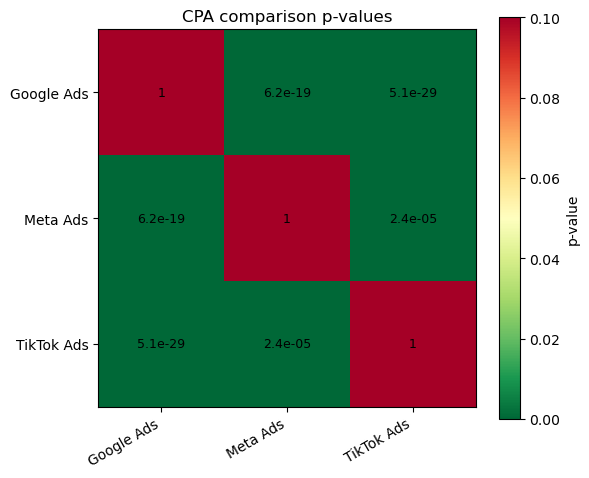

In [5]:
def pvalue_heatmap(pair_df, groups, title, filename):
    n = len(groups)
    matrix = np.ones((n, n))
    for _, row in pair_df.iterrows():
        i, j = groups.index(row['group_a']), groups.index(row['group_b'])
        matrix[i, j] = row['p_value']
        matrix[j, i] = row['p_value']
    np.fill_diagonal(matrix, 1.0)

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(matrix, cmap='RdYlGn_r', vmin=0, vmax=0.1)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(groups, rotation=30, ha='right')
    ax.set_yticklabels(groups)
    ax.set_title(title)

    for i in range(n):
        for j in range(n):
            ax.text(j, i, f'{matrix[i, j]:.2g}', ha='center', va='center', fontsize=9)

    fig.colorbar(im, ax=ax, label='p-value')
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

groups = sorted(daily['platform'].unique())
pvalue_heatmap(cpa_df, groups, 'CPA comparison p-values', 'metric_comparison_heatmap.png')

## Step 5: compare conversion rate with Fisher's exact test

CPA and ROAS are continuous. Conversions are a binary outcome (a click either converts or it does not), so a t-test on the rate is not the right tool here. Fisher's exact test compares the two rates directly from a 2x2 table of conversions vs non-conversions.

In [6]:
conv_agg = daily.groupby('platform', as_index=False).agg(
    conversions=('conversions', 'sum'),
    attempts=('clicks', 'sum'),
)
conv_agg['non_conversions'] = conv_agg['attempts'] - conv_agg['conversions']
conv_agg

,platform,conversions,attempts,non_conversions
0,Google Ads,131098,2936149,2805051
1,Meta Ads,73262,1596736,1523474
2,TikTok Ads,122452,2599931,2477479


In [7]:
def pairwise_fisher(agg_df, group_col='platform'):
    groups = sorted(agg_df[group_col].unique())
    rows = []
    for group_a, group_b in combinations(groups, 2):
        row_a = agg_df.loc[agg_df[group_col] == group_a].iloc[0]
        row_b = agg_df.loc[agg_df[group_col] == group_b].iloc[0]

        table = [[row_a['conversions'], row_a['non_conversions']],
                 [row_b['conversions'], row_b['non_conversions']]]
        odds_ratio, p_value = fisher_exact(table, alternative='two-sided')

        rate_a = row_a['conversions'] / row_a['attempts']
        rate_b = row_b['conversions'] / row_b['attempts']
        diff = rate_b - rate_a
        pct_diff = (diff / rate_a) * 100

        rows.append({
            'group_a': group_a, 'group_b': group_b,
            'conversions_a': row_a['conversions'], 'attempts_a': row_a['attempts'], 'rate_a': rate_a,
            'conversions_b': row_b['conversions'], 'attempts_b': row_b['attempts'], 'rate_b': rate_b,
            'diff': diff, 'pct_diff': pct_diff,
            'odds_ratio': odds_ratio, 'p_value': p_value,
            'significant': p_value < 0.05,
        })
        print(f"{group_a} ({rate_a:.4%}) vs {group_b} ({rate_b:.4%}) -> diff={diff:.4%} ({pct_diff:+.1f}%), "
              f"odds ratio={odds_ratio:.3f}, p={p_value:.4g}")

    return pd.DataFrame(rows)

fisher_df = pairwise_fisher(conv_agg)
print()
print(f"Total comparisons: {len(fisher_df)}, significant at alpha=0.05: {fisher_df['significant'].sum()}")
fisher_df

Google Ads (4.4650%) vs Meta Ads (4.5882%) -> diff=0.1233% (+2.8%), odds ratio=0.972, p=1.611e-09
Google Ads (4.4650%) vs TikTok Ads (4.7098%) -> diff=0.2449% (+5.5%), odds ratio=0.946, p=5.294e-43
Meta Ads (4.5882%) vs TikTok Ads (4.7098%) -> diff=0.1216% (+2.6%), odds ratio=0.973, p=9.537e-09

Total comparisons: 3, significant at alpha=0.05: 3


,group_a,group_b,conversions_a,attempts_a,rate_a,conversions_b,attempts_b,rate_b,diff,pct_diff,odds_ratio,p_value,significant
0,Google Ads,Meta Ads,131098,2936149,0.044650,73262,1596736,0.045882,0.001233,2.760848,0.971878,1.610840e-09,True
1,Google Ads,TikTok Ads,131098,2936149,0.044650,122452,2599931,0.047098,0.002449,5.483877,0.945582,5.294074e-43,True
2,Meta Ads,TikTok Ads,73262,1596736,0.045882,122452,2599931,0.047098,0.001216,2.649871,0.972944,9.537133e-09,True


### Visualize conversion rates by channel

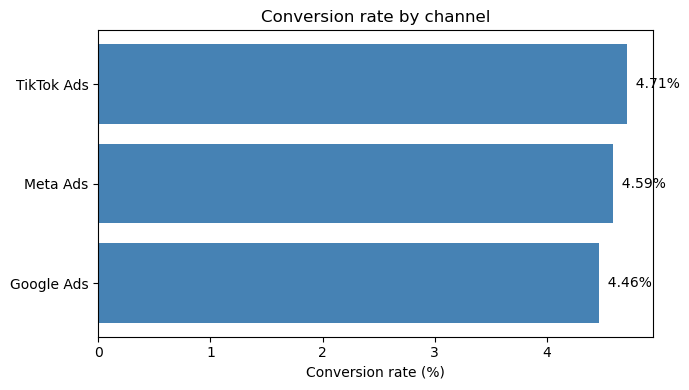

In [8]:
rate_table = conv_agg.assign(rate=lambda d: d['conversions'] / d['attempts']).sort_values('rate')

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(rate_table['platform'], rate_table['rate'] * 100, color='steelblue')
ax.set_xlabel('Conversion rate (%)')
ax.set_title('Conversion rate by channel')

for bar, rate in zip(bars, rate_table['rate']):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f'  {rate:.2%}', va='center')

plt.tight_layout()
plt.savefig('rate_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

**Note on these numbers:** with millions of clicks per channel, even a very small difference in conversion rate (a fraction of a percentage point) can come out as statistically significant, because the test has a huge sample size to work with. This is a good example of statistical significance not being the same as practical significance. Worth keeping in mind when I get to the correction step and the business recommendations.

## Step 6: multiple comparisons correction

I ran 3 CPA comparisons and 3 conversion rate comparisons, so 6 comparisons total. Even if there was no real difference anywhere, testing at alpha=0.05 means I would expect some of them to look "significant" just by chance. Correction adjusts for that.

In [9]:
total_comparisons = len(cpa_df) + len(fisher_df)
expected_false_positives = total_comparisons * 0.05

print(f"Total comparisons made (CPA + conversion rate): {total_comparisons}")
print(f"Expected false positives by chance alone, at alpha=0.05: {expected_false_positives:.2f}")
print()
print("This means even if none of these channels were actually different, we would still expect "
      f"about {expected_false_positives:.2f} 'significant' result out of {total_comparisons} just from random noise. "
      "Correction helps us tell a real difference apart from a lucky p-value.")

Total comparisons made (CPA + conversion rate): 6
Expected false positives by chance alone, at alpha=0.05: 0.30

This means even if none of these channels were actually different, we would still expect about 0.30 'significant' result out of 6 just from random noise. Correction helps us tell a real difference apart from a lucky p-value.


In [10]:
alpha = 0.05
alpha_bonferroni_cpa = alpha / len(cpa_df)
alpha_bonferroni_fisher = alpha / len(fisher_df)

cpa_df['significant_bonferroni'] = cpa_df['p_value'] < alpha_bonferroni_cpa
fisher_df['significant_bonferroni'] = fisher_df['p_value'] < alpha_bonferroni_fisher

print(f"Bonferroni adjusted alpha for CPA comparisons: {alpha_bonferroni_cpa:.4f}")
print(f"Bonferroni adjusted alpha for conversion rate comparisons: {alpha_bonferroni_fisher:.4f}")
print()
print(f"CPA comparisons still significant after Bonferroni: {cpa_df['significant_bonferroni'].sum()} of {len(cpa_df)}")
print(cpa_df.loc[cpa_df['significant_bonferroni'], ['group_a', 'group_b', 'p_value']])
print()
print(f"Conversion rate comparisons still significant after Bonferroni: {fisher_df['significant_bonferroni'].sum()} of {len(fisher_df)}")
print(fisher_df.loc[fisher_df['significant_bonferroni'], ['group_a', 'group_b', 'p_value']])

Bonferroni adjusted alpha for CPA comparisons: 0.0167
Bonferroni adjusted alpha for conversion rate comparisons: 0.0167

CPA comparisons still significant after Bonferroni: 3 of 3
      group_a     group_b       p_value
0  Google Ads    Meta Ads  6.159715e-19
1  Google Ads  TikTok Ads  5.126314e-29
2    Meta Ads  TikTok Ads  2.405082e-05

Conversion rate comparisons still significant after Bonferroni: 3 of 3
      group_a     group_b       p_value
0  Google Ads    Meta Ads  1.610840e-09
1  Google Ads  TikTok Ads  5.294074e-43
2    Meta Ads  TikTok Ads  9.537133e-09


In [11]:
cpa_df['p_value_fdr'] = false_discovery_control(cpa_df['p_value'], method='bh')
cpa_df['significant_fdr'] = cpa_df['p_value_fdr'] < alpha

fisher_df['p_value_fdr'] = false_discovery_control(fisher_df['p_value'], method='bh')
fisher_df['significant_fdr'] = fisher_df['p_value_fdr'] < alpha

print(f"CPA comparisons still significant after FDR: {cpa_df['significant_fdr'].sum()} of {len(cpa_df)}")
print(cpa_df.loc[cpa_df['significant_fdr'], ['group_a', 'group_b', 'p_value', 'p_value_fdr']])
print()
print(f"Conversion rate comparisons still significant after FDR: {fisher_df['significant_fdr'].sum()} of {len(fisher_df)}")
print(fisher_df.loc[fisher_df['significant_fdr'], ['group_a', 'group_b', 'p_value', 'p_value_fdr']])

CPA comparisons still significant after FDR: 3 of 3
      group_a     group_b       p_value   p_value_fdr
0  Google Ads    Meta Ads  6.159715e-19  9.239572e-19
1  Google Ads  TikTok Ads  5.126314e-29  1.537894e-28
2    Meta Ads  TikTok Ads  2.405082e-05  2.405082e-05

Conversion rate comparisons still significant after FDR: 3 of 3
      group_a     group_b       p_value   p_value_fdr
0  Google Ads    Meta Ads  1.610840e-09  2.416260e-09
1  Google Ads  TikTok Ads  5.294074e-43  1.588222e-42
2    Meta Ads  TikTok Ads  9.537133e-09  9.537133e-09


In [12]:
correction_summary = pd.DataFrame({
    'comparison_type': ['CPA', 'CPA', 'CPA', 'Conversion rate', 'Conversion rate', 'Conversion rate'],
    'method': ['Uncorrected', 'Bonferroni', 'FDR (BH)'] * 2,
    'significant_count': [
        cpa_df['significant'].sum(), cpa_df['significant_bonferroni'].sum(), cpa_df['significant_fdr'].sum(),
        fisher_df['significant'].sum(), fisher_df['significant_bonferroni'].sum(), fisher_df['significant_fdr'].sum(),
    ],
    'total_comparisons': [len(cpa_df)] * 3 + [len(fisher_df)] * 3,
})
correction_summary

,comparison_type,method,significant_count,total_comparisons
0,CPA,Uncorrected,3,3
1,CPA,Bonferroni,3,3
2,CPA,FDR (BH),3,3
3,Conversion rate,Uncorrected,3,3
4,Conversion rate,Bonferroni,3,3
5,Conversion rate,FDR (BH),3,3


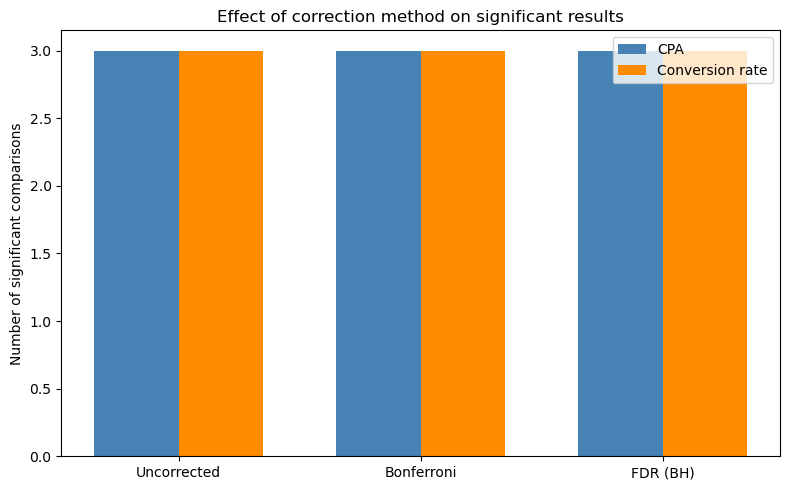

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

methods = ['Uncorrected', 'Bonferroni', 'FDR (BH)']
x = np.arange(len(methods))
width = 0.35

cpa_counts = correction_summary.loc[correction_summary['comparison_type'] == 'CPA', 'significant_count'].values
rate_counts = correction_summary.loc[correction_summary['comparison_type'] == 'Conversion rate', 'significant_count'].values

ax.bar(x - width / 2, cpa_counts, width, label='CPA', color='steelblue')
ax.bar(x + width / 2, rate_counts, width, label='Conversion rate', color='darkorange')

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel('Number of significant comparisons')
ax.set_title('Effect of correction method on significant results')
ax.legend()

plt.tight_layout()
plt.savefig('correction_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### Key insights

With only 3 channels I get 3 pairs per metric, 6 comparisons total, so the expected number of false positives by chance is small (about 0.3). In this dataset, every comparison stays significant even after Bonferroni and FDR correction, for both CPA and conversion rate. That is because the channels really are quite different in this data (Cohen's d ranges from small to large for CPA) and the sample sizes are large, especially for the conversion rate comparisons which are based on millions of clicks.

So correction did not flip any conclusion here, but that is still a useful result. It tells me these are not borderline, coincidental findings, they hold up even under a conservative correction. If more channels were being compared at once, or if the effects were more marginal, correction would likely have removed some of them. This matters directly for the budget conversation: I can be fairly confident that TikTok Ads and Google Ads really do differ on CPA, and it is not just noise.

One caveat to carry into the memo: the conversion rate differences, while statistically real, are small in absolute terms (well under 1 percentage point between channels). The CPA differences are larger in relative terms (roughly 20 to 53 percent apart) and probably matter more for a budget decision than the conversion rate gap does.